This notebook is dedicated to the analysis of the CSV results

In [1]:
# first we need to import our visualization libraries and any other related components

import json # need to parse geojson
import re # needed for wordcloud example

import matplotlib.pyplot as plt # 
import pandas as pd # using data frames with our plotly visualization
import plotly.express as px # px shorthand is used in plotly examples
import pydeck as pdk # pdk is used as a shorthand for pydeck examples

from IPython.display import HTML, IFrame # needed to display pydeck visualization in the notebook
from wordcloud import STOPWORDS, wordcloud #

In [2]:
%pip install matplotlib pandas plotly pydeck wordcloud

Note: you may need to restart the kernel to use updated packages.


In [3]:
nativeamerican = pd.read_csv("artworks_combined_3.csv")

nativeamerican.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,120950,False,1976.55,1976.0,True,https://images.metmuseum.org/CRDImages/ao/orig...,https://images.metmuseum.org/CRDImages/ao/web-...,[],NaN,The Michael C. Rockefeller Wing,...,Feathers-Costumes,NaN,NaN,2026-10-21T04:58:17.613Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,27229,False,1978.132.2,1978.0,False,NaN,NaN,[],NaN,Arms and Armor,...,Shafted Weapons,NaN,NaN,2025-03-06T04:54:30Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
2,500882,False,89.4.3560,1889.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Aerophone-Blow Hole-side-blown flute (transverse),NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
3,500888,False,06.1257,1906.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
4,500889,False,06.1258,1906.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412906,False,NaN


In [4]:
pd.set_option('display.max_rows', None)

nativeamerican['state'].value_counts()

state
British Columbia                               159
Nunavut                                        128
Oklahoma                                       124
Alaska                                          91
Arizona                                         84
Arizona or New Mexico                           52
New Mexico                                      43
California                                      32
Quebec                                          19
New York                                        12
Demerara                                        12
Minnesota                                        9
New Brunswick or Nova Scotia                     8
South Dakota                                     7
Washington                                       7
North Dakota or South Dakota                     6
Ontario                                          5
Wyoming                                          4
Florida                                          4
Maine                    

In [5]:
nativeamerican_with_state = pd.read_csv("artworks_combined_3_with_state.csv")

#preview what's in each file:
nativeamerican_with_state.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,500888,False,06.1257,1906.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,500889,False,06.1258,1906.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412906,False,NaN
2,501178,False,"89.4.562a, b",1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,"[{'constituentID': 155406, 'role': 'Maker', 'n...",Musical Instruments,...,Membranophone-single-headed / frame drum,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
3,501180,False,89.4.564,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Chordophone-Lute,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
4,501189,False,89.4.573,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Aerophone-Blow Hole-end-blown flute (vertical),NaN,NaN,2024-05-17T04:51:53.097Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN


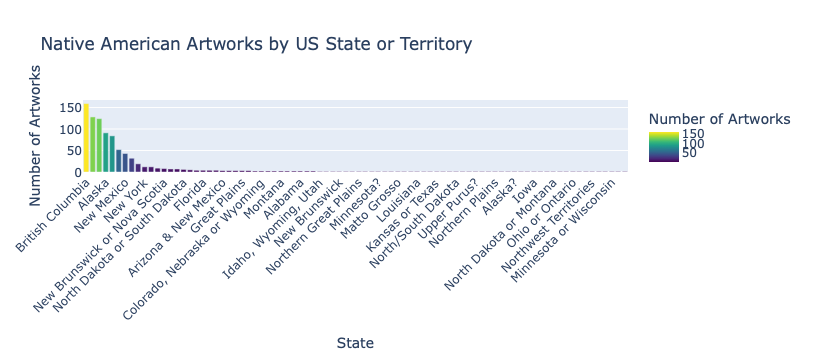

In [6]:
state_counts = nativeamerican_with_state["state"].value_counts().reset_index()

state_counts.columns = ["state", "artwork_count"]

# Create bar graph
fig = px.bar(
    state_counts,
    x="state",
    y="artwork_count",
    title="Native American Artworks by US State or Territory",
    labels={
        "state": "State",
        "artwork_count": "Number of Artworks"
    },
    color="artwork_count",
    color_continuous_scale="Viridis"
)

fig.update_layout(
    autosize=True,
    width=None,
    xaxis_title="State",
    yaxis_title="Number of Artworks",
    xaxis_tickangle=-45,
    xaxis={"categoryorder": "total descending"}
)

fig.show()

In [7]:
native_with_state_filtered = pd.read_csv("artworks_combined_3_with_state_cleaned.csv")

#preview what's in each file:
native_with_state_filtered.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,500888,False,06.1257,1906.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,500889,False,06.1258,1906.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412906,False,NaN
2,501180,False,89.4.564,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Chordophone-Lute,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
3,501197,False,89.4.581,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
4,501200,False,89.4.584,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Struck-bell-clapper,NaN,NaN,2024-03-22T04:53:07.663Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN


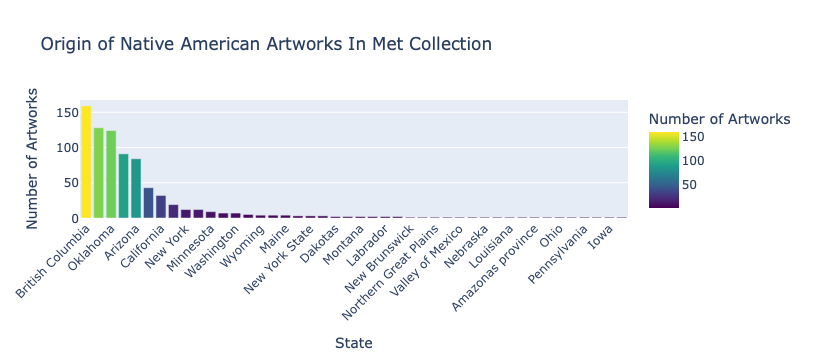

In [8]:
state_counts = native_with_state_filtered["state"].value_counts().reset_index()

state_counts.columns = ["state", "artwork_count"]

# Create bar graph
fig = px.bar(
    state_counts,
    x="state",
    y="artwork_count",
    title="Origin of Native American Artworks In Met Collection",
    labels={
        "state": "State",
        "artwork_count": "Number of Artworks"
    },
    color="artwork_count",
    color_continuous_scale="Viridis"
)

fig.update_layout(
    autosize=True,
    width=None,
    xaxis_title="State",
    yaxis_title="Number of Artworks",
    xaxis_tickangle=-45,
    xaxis={"categoryorder": "total descending"}
)

fig.show()

In [9]:
pip install wordcloud matplotlib

Note: you may need to restart the kernel to use updated packages.


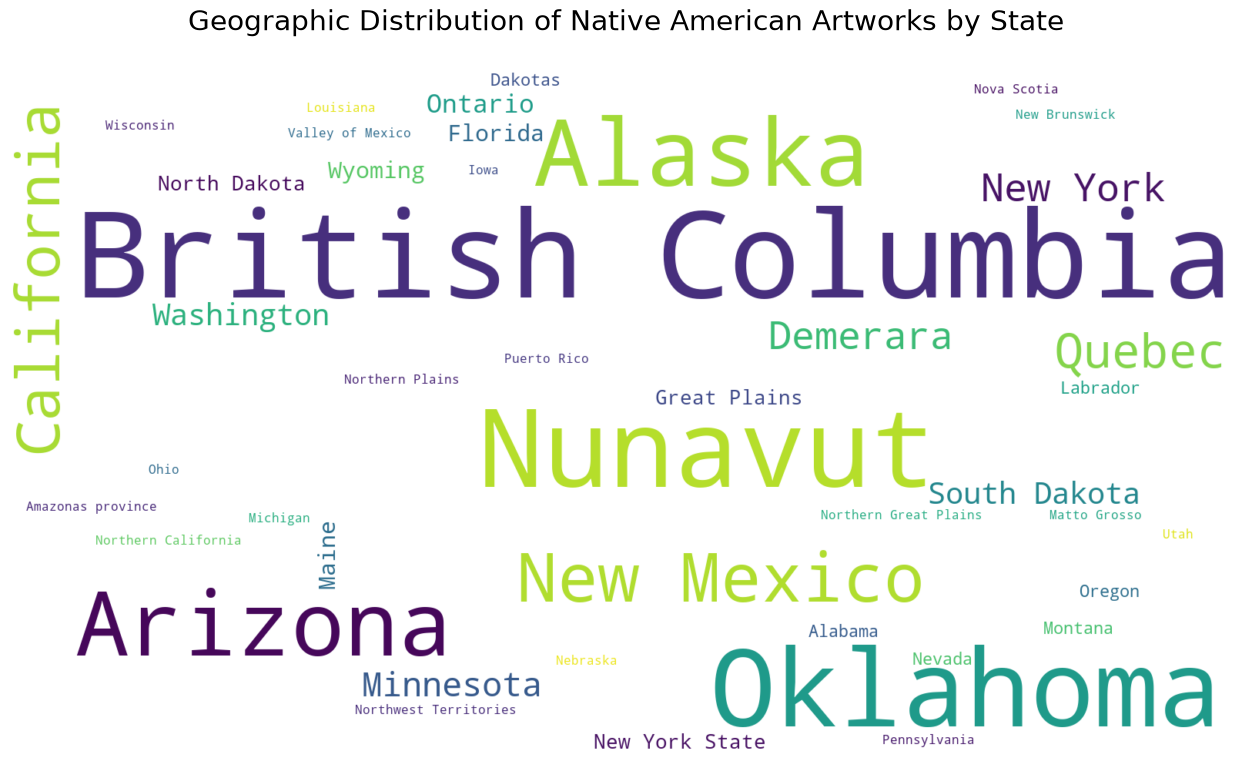

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Read your CSV
df = pd.read_csv("artworks_combined_3_with_state_cleaned.csv")

# Calculate the frequency of each state
state_counts = df["state"].dropna().value_counts()

# Convert counts into a dictionary
state_freq = state_counts.to_dict()

# Generate the word cloud
wordcloud = WordCloud(
    width=1600,
    height=900,
    background_color="white",
    colormap="viridis",
    prefer_horizontal=0.9,
    max_words=100
).generate_from_frequencies(state_freq)

# Display the word cloud
plt.figure(figsize=(16, 9))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Geographic Distribution of Native American Artworks by State",
          fontsize=20, pad=20)

plt.show()

# Save as PNG
# wordcloud.to_file("state_wordcloud.png")

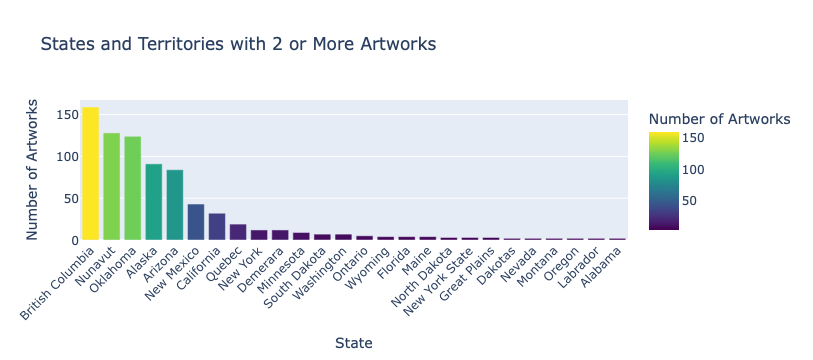

In [11]:
# Count artworks by state
state_counts = native_with_state_filtered["state"].value_counts().reset_index()

state_counts.columns = ["state", "artwork_count"]

# Remove states with only 1 artwork
state_counts = state_counts[state_counts["artwork_count"] > 1] # added to make chart more readable

# Create bar graph
fig = px.bar(
    state_counts,
    x="state",
    y="artwork_count",
    title="States and Territories with 2 or More Artworks",
    labels={
        "state": "State or Territory",
        "artwork_count": "Number of Artworks"
    },
    color="artwork_count",
    color_continuous_scale="Viridis"
)

fig.update_layout(
    autosize=True,
    width=None,
    xaxis_title="State",
    yaxis_title="Number of Artworks",
    xaxis_tickangle=-45,
    xaxis={"categoryorder": "total descending"}
)

fig.show()
fig.write_image("state_bargraph.png")

In [13]:
# repeating for largest groups in the dataset: Cheyenne

#get coordinates from OpenStreetMap
import pandas as pd
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

# Read your CSV
df = pd.read_csv("cheyenne_with_state_cleaned.csv")

# Clean up state names
df["state"] = df["state"].str.strip()

# Initialize OpenStreetMap geocoder
geolocator = Nominatim(user_agent="cheyenne_artwork_geocoder")

# Add a 1-second delay between requests
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1
)

# Dictionary to store coordinates
coordinates = {}

# Geocode each unique state
for state in df["state"].dropna().unique():

    # Skip regional labels that aren't states
    if state in ["Great Plains", "Dakotas"]:
        continue

    location = geocode(f"{state}, USA")

    if location:
        coordinates[state] = {
            "latitude": location.latitude,
            "longitude": location.longitude
        }
    else:
        coordinates[state] = {
            "latitude": None,
            "longitude": None
        }

# Add latitude and longitude columns
df["latitude"] = df["state"].map(
    lambda x: coordinates.get(x, {}).get("latitude")
)

df["longitude"] = df["state"].map(
    lambda x: coordinates.get(x, {}).get("longitude")
)

# Export updated CSV
df.to_csv("cheyenne_with_state_coordinates.csv", index=False)

print(df[["state", "latitude", "longitude"]])

        state   latitude   longitude
0    Oklahoma  34.955082  -97.268406
1    Oklahoma  34.955082  -97.268406
2    Oklahoma  34.955082  -97.268406
3    Oklahoma  34.955082  -97.268406
4     Wyoming  43.170026 -107.568534
5    Oklahoma  34.955082  -97.268406
6    Oklahoma  34.955082  -97.268406
7    Oklahoma  34.955082  -97.268406
8    Oklahoma  34.955082  -97.268406
9    Oklahoma  34.955082  -97.268406
10   Oklahoma  34.955082  -97.268406
11   Oklahoma  34.955082  -97.268406
12   Oklahoma  34.955082  -97.268406
13   Oklahoma  34.955082  -97.268406
14   Oklahoma  34.955082  -97.268406
15   Oklahoma  34.955082  -97.268406
16   Oklahoma  34.955082  -97.268406
17   Oklahoma  34.955082  -97.268406
18   Oklahoma  34.955082  -97.268406
19   Oklahoma  34.955082  -97.268406
20   Oklahoma  34.955082  -97.268406
21   Oklahoma  34.955082  -97.268406
22   Oklahoma  34.955082  -97.268406
23   Oklahoma  34.955082  -97.268406
24   Oklahoma  34.955082  -97.268406
25   Oklahoma  34.955082  -97.268406
2

In [14]:
# redo for a better more interestign result. 
# Trying all inuit artworks and trying to be as specific as possible

# Find all records where culture contains Inuit
inuit = df[
    df["culture"].str.contains("inuit", case=False, na=False)
].copy()

# Select geographic columns and count combinations
inuit_locations = (
    inuit.groupby(
        ["city", "state", "country", "region"],
        dropna=False
    )
    .size()
    .reset_index(name="artwork_count")
    .sort_values("artwork_count", ascending=False)
)

print(inuit_locations.to_string(index=False))

Empty DataFrame
Columns: [city, state, country, region, artwork_count]
Index: []


In [15]:
# Find all records where culture contains Inuit
inuit = df[
    df["culture"].astype("string").str.contains(
        "inuit", case=False, na=False
    )
].copy()

# Select geographic columns and count combinations
inuit_locations = (
    inuit.groupby(
        ["city", "state", "country", "region"],
        dropna=False
    )
    .size()
    .reset_index(name="artwork_count")
    .sort_values("artwork_count", ascending=False)
)

# Save results as a new CSV
inuit_locations.to_csv(
    "inuit_geographic_locations.csv",
    index=False
)

# Display confirmation
print("Total Inuit records:", len(inuit))
print("Unique geographic combinations:", len(inuit_locations))
print("New CSV saved: inuit_geographic_locations.csv")

Total Inuit records: 0
Unique geographic combinations: 0
New CSV saved: inuit_geographic_locations.csv


In [16]:
import pandas as pd

df = pd.read_csv("artworks_combined_3_with_state_cleaned.csv")

# Remove leading/trailing spaces from culture values
df["culture"] = df["culture"].astype("string").str.strip()

# Find Inuit records
inuit = df[
    df["culture"].str.contains("Inuit", case=False, na=False)
].copy()

print("Total Inuit records:", len(inuit))

Total Inuit records: 178


In [17]:
# make a new CSV with Inuit artworks only. 
# Making groupings based on geographic data combinations in order to make a map that is as specific as possible.

geo_cols = [
    "city",
    "state",
    "county",
    "country",
    "region",
    "subregion",
    "locale",
    "locus",
    "excavation",
    "river"
]

inuit_locations = (
    inuit.groupby(geo_cols, dropna=False)
    .size()
    .reset_index(name="artwork_count")
    .sort_values("artwork_count", ascending=False)
)

# Export to CSV
inuit_locations.to_csv(
    "inuit_geographic_locations.csv",
    index=False
)

print("Total Inuit records:", len(inuit))
print("Unique geographic combinations:", len(inuit_locations))
print("Saved: inuit_geographic_locations.csv")

Total Inuit records: 178
Unique geographic combinations: 22
Saved: inuit_geographic_locations.csv


In [18]:
import pandas as pd

places = pd.read_csv("inuit_geographic_locations.csv")

print("Locations to geocode:", len(places))
print(places.head())

Locations to geocode: 22
  city    state  county        country           region  subregion  locale  \
0  NaN  Nunavut     NaN         Canada    Baffin Island        NaN     NaN   
1  NaN   Alaska     NaN  United States              NaN        NaN     NaN   
2  NaN   Quebec     NaN         Canada              NaN        NaN     NaN   
3  NaN  Nunavut     NaN         Canada  Belcher Islands        NaN     NaN   
4  NaN  Nunavut     NaN         Canada              NaN        NaN     NaN   

   locus  excavation       river  artwork_count  
0    NaN         NaN         NaN             80  
1    NaN         NaN         NaN             30  
2    NaN         NaN  Hudson Bay             14  
3    NaN         NaN  Hudson Bay             13  
4    NaN         NaN  Hudson Bay              9  


In [19]:

import pandas as pd
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from pathlib import Path

# Input and output files
input_file = "inuit_geographic_locations.csv"
output_file = "inuit_geographic_locations_with_coordinates.csv"

places = pd.read_csv(input_file)

# Geographic fields, from most specific to broadest
query_order = [
    "city",
    "locale",
    "locus",
    "excavation",
    "region",
    "subregion",
    "river",
    "county",
    "state",
    "country"
]

# Build search queries
def build_query(row):
    values = []

    for col in query_order:
        if col in row.index:
            value = row[col]

            if pd.notna(value) and str(value).strip():
                values.append(str(value).strip())

    # Remove duplicate values while preserving order
    values = list(dict.fromkeys(values))

    return ", ".join(values)


places["geocode_query"] = places.apply(build_query, axis=1)

# Initialize OpenStreetMap geocoder
geolocator = Nominatim(
    user_agent="Pratt_INFO664_met_artwork_geographic_research_2026"
)

# Limit requests to one per 1.1 seconds
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1,
    max_retries=2,
    error_wait_seconds=5,
    swallow_exceptions=True
)

# Retrieve coordinates and matching information
def get_coordinates(query):

    if not query:
        return pd.Series({
            "latitude": None,
            "longitude": None,
            "matched_location": None,
            "osm_type": None,
            "osm_id": None
        })

    location = geocode(query, addressdetails=True)

    if location:
        return pd.Series({
            "latitude": location.latitude,
            "longitude": location.longitude,
            "matched_location": location.address,
            "osm_type": location.raw.get("type"),
            "osm_id": location.raw.get("osm_id")
        })

    return pd.Series({
        "latitude": None,
        "longitude": None,
        "matched_location": None,
        "osm_type": None,
        "osm_id": None
    })


# Geocode each unique geographic combination
results = places["geocode_query"].apply(get_coordinates)

# Add results to original geographic data
places = pd.concat([places, results], axis=1)

# Save new CSV
places.to_csv(output_file, index=False)

# Display summary
print("Total locations:", len(places))
print("Successfully geocoded:", places["latitude"].notna().sum())
print("Unmatched locations:", places["latitude"].isna().sum())
print("Saved:", output_file)


Total locations: 22
Successfully geocoded: 16
Unmatched locations: 6
Saved: inuit_geographic_locations_with_coordinates.csv


In [20]:
# checking for unmatched results
unmatched = places[places["latitude"].isna()]

print(unmatched[[
    "geocode_query"
]].to_string(index=False))

                                                  geocode_query
                   Belcher Islands, Hudson Bay, Nunavut, Canada
                   Baffin Island, Patricia Bay, Nunavut, Canada
                     Baffin Island, Hudson Bay, Nunavut, Canada
                  Baffin Island, Frobisher Bay, Nunavut, Canada
Mackenzie Delta, Mackenzie River, Northwest Territories, Canada
                              Povungnituk River, Quebec, Canada


In [22]:
#Clean-up. Appending some lines manually. 
# Load your geocoded CSV
places = pd.read_csv(
    "inuit_geographic_locations_with_coordinates.csv"
)

# Manually researched coordinates
manual_coordinates = {
    "Belcher Islands, Hudson Bay, Nunavut, Canada": {
        "latitude": 56.176,
        "longitude": -79.277
    },
    # i discovered the order is actually switched and should read Patricia Bay, Baffin Island. Thats why it didn't work.
    "Baffin Island, Patricia Bay, Nunavut, Canada": { 
        "latitude": 70.37,
        "longitude": -68.55
    },
    "Baffin Island, Hudson Bay, Nunavut, Canada": { # decided to default to Baffin Island bc hudson Bay would put it in the ocean.
    #these coordinates are from wikipedia. No coordinates for Baffin Island in Open street Map!!!
        "latitude": 68,
        "longitude":-70
    },
    "Baffin Island, Frobisher Bay, Nunavut, Canada": { #coordinates for the bay
        "latitude": 63.7526,
        "longitude":-68.5210
    },
    "Mackenzie Delta, Mackenzie River, Northwest Territories, Canada": { #this river is hella long... defaulting to the delta
        "latitude": 68.082,
        "longitude":-134.857
    },
    "Povungnituk River, Quebec, Canada": { #coordinates are for the center of the river.
        "latitude": 61.119,
        "longitude":-75.811
    }

}

# Fill in missing coordinates
for query, coords in manual_coordinates.items():

    mask = places["geocode_query"] == query

    places.loc[mask, "latitude"] = coords["latitude"]
    places.loc[mask, "longitude"] = coords["longitude"]

    places.loc[mask, "coordinate_source"] = "Manual"

# Mark existing OSM coordinates
places.loc[
    places["latitude"].notna() &
    places["coordinate_source"].isna(),
    "coordinate_source"
] = "OpenStreetMap"

# Save updated CSV
places.to_csv(
    "inuit_geographic_locations_final.csv",
    index=False
)

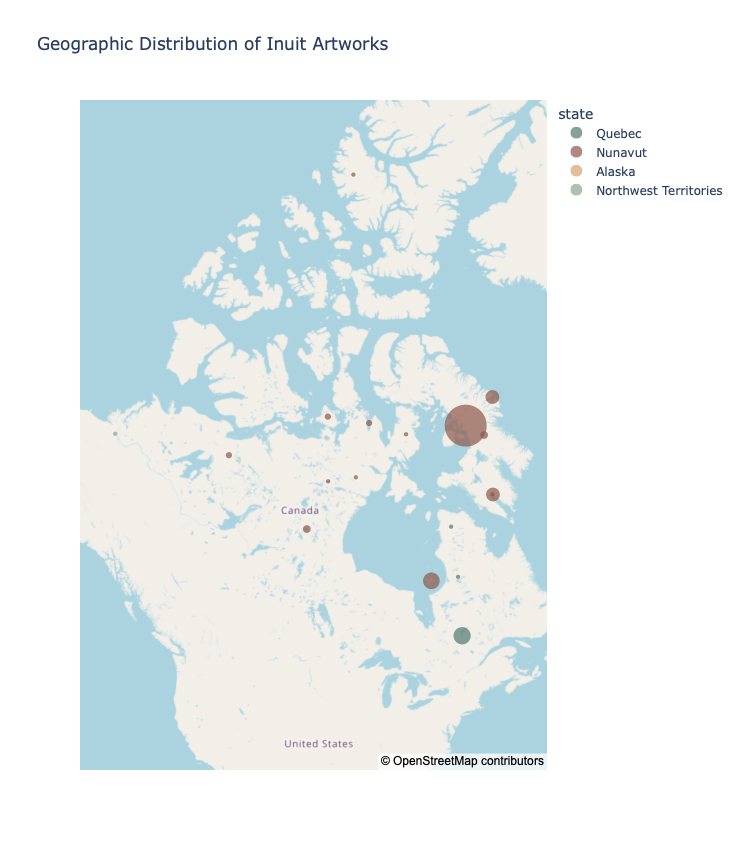

In [26]:
import pandas as pd
import plotly.express as px

# Load the new CSV
df = pd.read_csv("inuit_geographic_locations_final.csv")

# Remove rows without coordinates, just in case
df = df.dropna(subset=["latitude", "longitude"]).copy()

# Create a label for each geographic location
df["location_label"] = df["geocode_query"].fillna("Unknown location")

# Combine records that have identical coordinates
# This prevents overlapping markers (e.g., the two Point Barrow entries)
map_data = (
    df.groupby(["latitude", "longitude", "state", "country"], dropna=False)
    .agg(
        artwork_count=("artwork_count", "sum"),
        locations=("location_label", lambda x: "; ".join(x.unique())),
        coordinate_sources=(
            "coordinate_source",
            lambda x: ", ".join(x.dropna().unique())
        ),
        matched_locations=(
            "matched_location",
            lambda x: "; ".join(x.dropna().unique())
        )
    )
    .reset_index()
)

# Colors for each state / territory
custom_colors = {
    "Nunavut": "#8C564B",
    "Alaska": "#D4A373",
    "Quebec": "#52796F",
    "Northwest Territories": "#84A98C"
}

# Create interactive map
fig = px.scatter_map(
    map_data,
    lat="latitude",
    lon="longitude",
    color="state",
    color_discrete_map=custom_colors,
    size="artwork_count",
    size_max=30,
    hover_name="locations",
    hover_data={
        "state": True,
        "country": True,
        "artwork_count": True,
        "matched_locations": True,
        "coordinate_sources": True,
        "latitude": False,
        "longitude": False
    },
    zoom=2,
    center={"lat": 68, "lon": -100},
    map_style="open-street-map",
    title="Geographic Distribution of Inuit Artworks",
    height=850,
    width=1200
)

fig.show()

After reviewing, this might be unusable. Husdon Bay is returning a department store, not the bay region. Baffin island returned the airport, not the island itself. it was an interesting idea and exercise but ultimately not going to work

In [27]:
# focusing on my big map

# Read the bigger CSV
df_all = pd.read_csv("artworks_combined_3_with_state_cleaned.csv")


In [28]:
df_all['country'].value_counts()

country
United States    450
Canada           309
Guyana            12
Canada: N.A.       7
Brazil             2
Mexico             1
Name: count, dtype: int64

In [37]:
df_all[df_all["country"] == "United States"]["state"].value_counts()

state
Oklahoma               123
Alaska                  91
Arizona                 84
New Mexico              43
California              32
New York                12
Minnesota                9
South Dakota             7
Washington               7
Wyoming                  4
Florida                  4
Maine                    4
North Dakota             3
New York State           3
Great Plains             3
Dakotas                  2
Nevada                   2
Montana                  2
Oregon                   2
Alabama                  2
Northern California      1
Nebraska                 1
Utah                     1
Louisiana                1
Michigan                 1
Puerto Rico              1
Ohio                     1
Northern Plains          1
Pennsylvania             1
Wisconsin                1
Iowa                     1
Name: count, dtype: int64

In [45]:
# to avoid the rate limit error
from geopy.extra.rate_limiter import RateLimiter

geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1,
    max_retries=3,
    error_wait_seconds=5
)

# Read your CSV
df = pd.read_csv("artworks_combined_3_with_state_cleaned.csv")

# Clean up state names
df["state"] = df["state"].str.strip()

# Initialize OpenStreetMap geocoder
geolocator = Nominatim(user_agent="nativeamerican_artwork_geocoder")

# Add a 1-second delay between requests
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1
)

# Dictionary to store coordinates
coordinates = {}

# Geocode each unique state
for state in df["state"].dropna().unique():

    # Skip regional labels that aren't states
    if state in ["British Columbia", 
    "Demerara", 
    "Ontario",
    "Great Plains",
    "Quebec",
    "Dakotas",
    "Matto Grosso",
    "Nunavut",
    "Valley of Mexico",
    "Northern Plains",
    "Nova Scotia",
    "New Brunswick",
    "Northwest Territories",
    "Labrador",
    "Northern Great Plains",
    "Amazonas province"]:
        continue

    location = geocode(f"{state}, USA")

    if location:
        coordinates[state] = {
            "latitude": location.latitude,
            "longitude": location.longitude
        }
    else:
        coordinates[state] = {
            "latitude": None,
            "longitude": None
        }

# Add latitude and longitude columns
df["latitude"] = df["state"].map(
    lambda x: coordinates.get(x, {}).get("latitude")
)

df["longitude"] = df["state"].map(
    lambda x: coordinates.get(x, {}).get("longitude")
)

# Export updated CSV
df.to_csv("artworks_combined_3_with_state_cleaned_coordinates.csv", index=False)

print(df[["state", "latitude", "longitude"]])

                     state   latitude   longitude
0                 New York  40.712728  -74.006015
1                 New York  40.712728  -74.006015
2                   Alaska  64.445961 -149.680909
3                   Alaska  64.445961 -149.680909
4                  Arizona  34.395342 -111.763275
5                   Alaska  64.445961 -149.680909
6                  Arizona  34.395342 -111.763275
7               New Mexico  34.580207 -105.996047
8               New Mexico  34.580207 -105.996047
9         British Columbia        NaN         NaN
10                  Alaska  64.445961 -149.680909
11                 Arizona  34.395342 -111.763275
12                 Arizona  34.395342 -111.763275
13              New Mexico  34.580207 -105.996047
14                  Alaska  64.445961 -149.680909
15                Demerara        NaN         NaN
16        British Columbia        NaN         NaN
17           New Brunswick        NaN         NaN
18                 Dakotas        NaN         NaN


In [32]:
import pandas as pd
import plotly.express as px

# Read your updated CSV
df2 = pd.read_csv("artworks_combined_3_with_state_cleaned_coordinates.csv")

# Remove rows without coordinates
df2 = df2.dropna(subset=["latitude", "longitude"])

# Preview your data
df2.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,latitude,longitude
0,500888,False,06.1257,1906.0,False,NaN,NaN,[],NaN,Musical Instruments,...,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,40.712728,-74.006015
1,500889,False,06.1258,1906.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412906,False,NaN,40.712728,-74.006015
2,501180,False,89.4.564,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,64.445961,-149.680909
3,501197,False,89.4.581,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,64.445961,-149.680909
4,501200,False,89.4.584,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,NaN,2024-03-22T04:53:07.663Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,34.395342,-111.763275


In [46]:
df3 = pd.read_csv('artworks_combined_3_with_state_cleaned_coordinates.csv')

print(df3.loc[
    df3["state"] == "Northern Great Plains",
    ["latitude", "longitude"] # print only these columns
])

    latitude  longitude
24       NaN        NaN


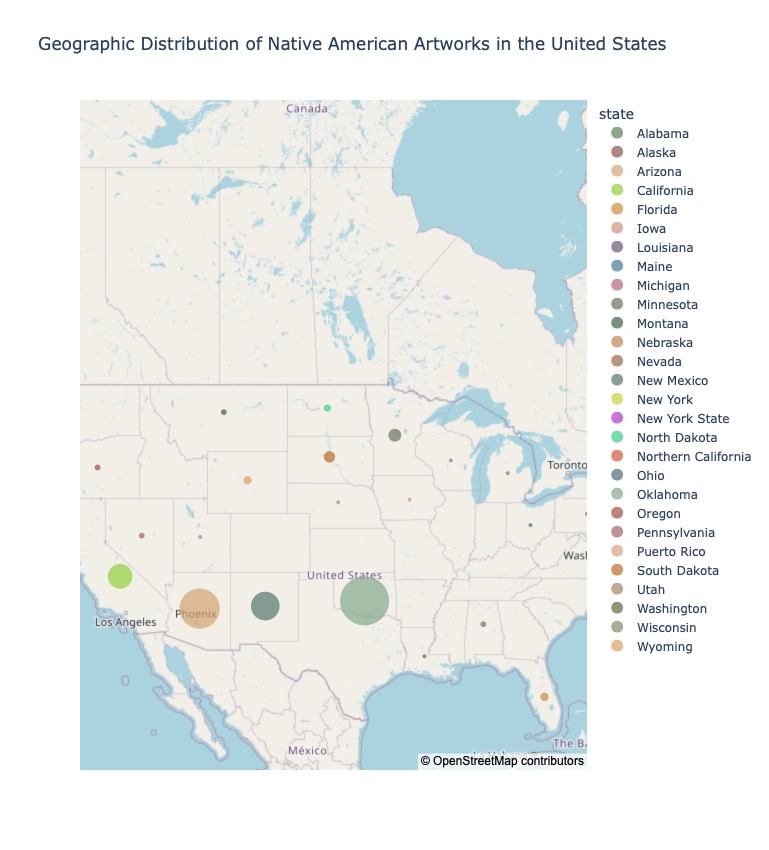

In [47]:
# I want to include the data from the 'culture column.' I decided to add Culture as I hovered over the bubbles, so I added 'culture' as another group.
# the dots will still be states


import pandas as pd
import plotly.express as px

# Custom state colors
custom_colors = {
    "Alaska": "#8C564B",
    "Arizona": "#D4A373",
    "New Mexico": "#52796F",
    "Oklahoma": "#84A98C",
    "South Dakota": "#BC6C25",
    "Washington": "#606C38",
    "Wyoming": "#DDA15E",
    "Minnesota": "#6B705C",
    "Oregon": "#A44A3F",
    "Nevada": "#9C6644",
    "Alabama": "#588157",
    "Nebraska": "#C08552",
    "Maine": "#457B9D",
    "Utah": "#A98467",
    "Montana": "#386641",
    "Michigan": "#B56576",
    "Louisiana": "#6D597A",
    "Puerto Rico": "#E09F7D",
    "Ohio": "#4F6D7A",
    "Pennsylvania": "#A26769",
    "Wisconsin": "#7F8C69",
    "Iowa": "#CB997E",
    "California": "#91D039",
    "Florida": "#D08B39",
    "New York": "#C4D039",
    "New York State": "#B139D0",
    "North Dakota": "#39D084",
    "Northern California": "#D05839",
    "Unknown": "#808080"
}

# Replace missing culture values
df3["culture"] = df3["culture"].fillna("Unknown")

# Remove rows without coordinates
df3 = df3.dropna(subset=["latitude", "longitude"])

# Count artworks by state and culture
culture_counts = (
    df3.groupby(["state", "culture"])
    .size()
    .unstack(fill_value=0)
)

# Count total artworks and get coordinates by state
state_summary = (
    df3.groupby("state")
    .agg(
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
        total_artworks=("state", "size")
    )
)

# Combine state totals with culture counts
state_summary = state_summary.join(culture_counts)

# Reset index for Plotly
state_summary = state_summary.reset_index()

# Identify culture columns
culture_columns = culture_counts.columns.tolist()

# Create interactive map
fig = px.scatter_map(
    state_summary,
    lat="latitude",
    lon="longitude",
    color="state",
    color_discrete_map=custom_colors,
    size="total_artworks",
    size_max=35,
    hover_name="state",
    hover_data={
        "latitude": False,
        "longitude": False,
        "total_artworks": True,
        **{culture: True for culture in culture_columns}
    },
    zoom=3,
    center={"lat": 46, "lon": -100},
    map_style="open-street-map",
    title="Geographic Distribution of Native American Artworks in the United States",
    height=850,
    width=1200
)

fig.show()